# Statistical Characterization of Thesis Datasets

Notebook for exploratory/statistical analysis of the datasets used in the GA-based automatic decision-tree inducer.

In [1]:
# =========================
# 0. Imports and setup
# =========================

from pathlib import Path
import sys
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import entropy, skew, kurtosis, zscore, kruskal, f_oneway
from scipy.spatial.distance import jensenshannon

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.feature_selection import mutual_info_classif, chi2

random.seed(42)
np.random.seed(42)


In [ ]:
# =========================
# 1. Project root and datasets
# =========================

from pathlib import Path
import sys

def find_project_root(start: Path, marker="core"):
    for parent in [start] + list(start.parents):
        if (parent / marker).exists():
            return parent
    return start

PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

random.seed(42)
data_path = PROJECT_ROOT / "data"

datasets = {
    "abalone": data_path / "abalone.csv",
    "anneal": data_path / "anneal.csv",
    "arrhythmia": data_path / "arrhythmia.csv",
    "bridges": data_path / "bridges_version1.csv",
    "balance_scale": data_path / "balance_scale.csv",
    "car": data_path / "car.csv",
    "cylinder_bands": data_path / "cylinder_bands.csv",
    "glass": data_path / "glass.csv",
    "heart_disease": data_path / "heart_disease.csv",
    "ionosphere": data_path / "ionosphere.csv",
    "semeion": data_path / "semeion.csv",
    "sonar": data_path / "sonar.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "wine_red": data_path / "winequality_red.csv",
    "iris": data_path / "iris.csv",
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "banknote": data_path / "banknote_authentication.csv",
    "credit_approval": data_path / "credit_approval.csv",
}

# Edit this list to only include the datasets to analyse
selected_dataset_names = list(datasets.keys())
datasets = {name: path for name, path in datasets.items() if name in selected_dataset_names}

print("Project root:", PROJECT_ROOT)
print("Data path:", data_path)
print("Datasets selected:", list(datasets.keys()))


Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees
Data path: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\data
Datasets selected: ['abalone', 'anneal', 'arrhythmia', 'bridges', 'balance_scale', 'car', 'cylinder_bands', 'glass', 'heart_disease', 'ionosphere', 'semeion', 'sonar', 'tic_tac_toe', 'breast_cancer', 'wine_red', 'iris', 'haberman', 'parkinsons', 'banknote', 'credit_approval']


## 2. Target-column handling

By default, the notebook assumes that the **last column** is the target. If a file has another target column, add it to `TARGET_OVERRIDES`.

In [3]:
# =========================
# 2. Target configuration and loader
# =========================

TARGET_OVERRIDES = {
    # "heart_disease": "target",
    # "iris": "class",
    # "wine_red": "quality",
}

MISSING_TOKENS = ["?", "NA", "N/A", "na", "n/a", "", " ", "null", "None"]


def load_dataset(name, path):
    # Load a CSV and split into X and y.
    df = pd.read_csv(path, na_values=MISSING_TOKENS)
    df.columns = [str(c).strip() for c in df.columns]

    target_col = TARGET_OVERRIDES.get(name, df.columns[-1])
    if target_col not in df.columns:
        raise ValueError(f"Target column {target_col} not found in {name}. Available columns: {list(df.columns)}")

    X = df.drop(columns=[target_col]).copy()
    y = df[target_col].copy()

    valid_target = ~y.isna()
    X = X.loc[valid_target].reset_index(drop=True)
    y = y.loc[valid_target].reset_index(drop=True)

    y_encoded = LabelEncoder().fit_transform(y.astype(str))
    return df, X, y_encoded, target_col

loaded = {}
for name, path in datasets.items():
    try:
        df, X, y, target_col = load_dataset(name, path)
        loaded[name] = {"df": df, "X": X, "y": y, "target_col": target_col}
        print(f"Loaded {name}: {X.shape[0]} rows, {X.shape[1]} features, target='{target_col}'")
    except Exception as e:
        print(f"[ERROR] Could not load {name}: {e}")


Loaded abalone: 4177 rows, 8 features, target='target'
Loaded anneal: 798 rows, 38 features, target='target'
Loaded arrhythmia: 452 rows, 279 features, target='target'
Loaded bridges: 108 rows, 11 features, target='target'
Loaded balance_scale: 625 rows, 4 features, target='4'
Loaded car: 1728 rows, 6 features, target='target'
Loaded cylinder_bands: 540 rows, 39 features, target='target'
Loaded glass: 214 rows, 9 features, target='target'
Loaded heart_disease: 303 rows, 13 features, target='13'
Loaded ionosphere: 351 rows, 34 features, target='34'
Loaded semeion: 1593 rows, 256 features, target='target'
Loaded sonar: 208 rows, 60 features, target='60'
Loaded tic_tac_toe: 958 rows, 9 features, target='9'
Loaded breast_cancer: 569 rows, 30 features, target='target'
Loaded wine_red: 1599 rows, 11 features, target='target'
Loaded iris: 150 rows, 4 features, target='target'
Loaded haberman: 306 rows, 3 features, target='3'
Loaded parkinsons: 196 rows, 23 features, target='23'
Loaded banknot

## 3. Dataset-level summary

This gives sample size, dimensionality, class count, missingness, imbalance ratio, and class entropy.

In [4]:
# =========================
# 3. Dataset-level summary
# =========================

def class_entropy(y):
    counts = np.bincount(y)
    probs = counts / counts.sum()
    return entropy(probs, base=2)


def imbalance_ratio(y):
    counts = np.bincount(y)
    return counts.max() / counts.min() if counts.min() > 0 else np.inf

summary_rows = []
class_distribution_rows = []

for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    n_rows, n_features = X.shape
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    counts = pd.Series(y).value_counts(normalize=False).sort_index()
    props = pd.Series(y).value_counts(normalize=True).sort_index()

    summary_rows.append({
        "dataset": name,
        "n_samples": n_rows,
        "n_features": n_features,
        "n_numeric": len(numeric_cols),
        "n_categorical": len(categorical_cols),
        "n_classes": len(np.unique(y)),
        "missing_pct": X.isna().mean().mean() * 100,
        "class_entropy": class_entropy(y),
        "imbalance_ratio": imbalance_ratio(y),
        "samples_per_feature": n_rows / max(n_features, 1),
    })

    for cls in counts.index:
        class_distribution_rows.append({
            "dataset": name,
            "class": cls,
            "count": counts.loc[cls],
            "proportion": props.loc[cls],
        })

summary_df = pd.DataFrame(summary_rows).sort_values("dataset")
class_distribution_df = pd.DataFrame(class_distribution_rows)

output_dir = PROJECT_ROOT / "results" / "dataset_statistics"
output_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(output_dir / "dataset_summary.csv", index=False)
class_distribution_df.to_csv(output_dir / "class_distribution.csv", index=False)

summary_df


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature
0,abalone,4177,8,7,1,28,0.000000,3.602007,689.000000,522.125000
1,anneal,798,38,16,22,5,64.938662,1.190925,76.000000,21.000000
2,arrhythmia,452,279,279,0,13,0.323532,2.401386,122.500000,1.620072
4,balance_scale,625,4,3,1,5,0.000000,2.321928,1.000000,156.250000
18,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000
13,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667
3,bridges,108,11,4,7,8,6.313131,2.461855,44.000000,9.818182
5,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000
19,credit_approval,690,15,6,9,2,0.647343,0.991231,1.247557,46.000000
6,cylinder_bands,540,39,24,15,2,4.743590,0.982474,1.368421,13.846154


## 4. Class balance plots

Important for macro-F1 and for understanding whether a tree may bias itself toward majority classes.

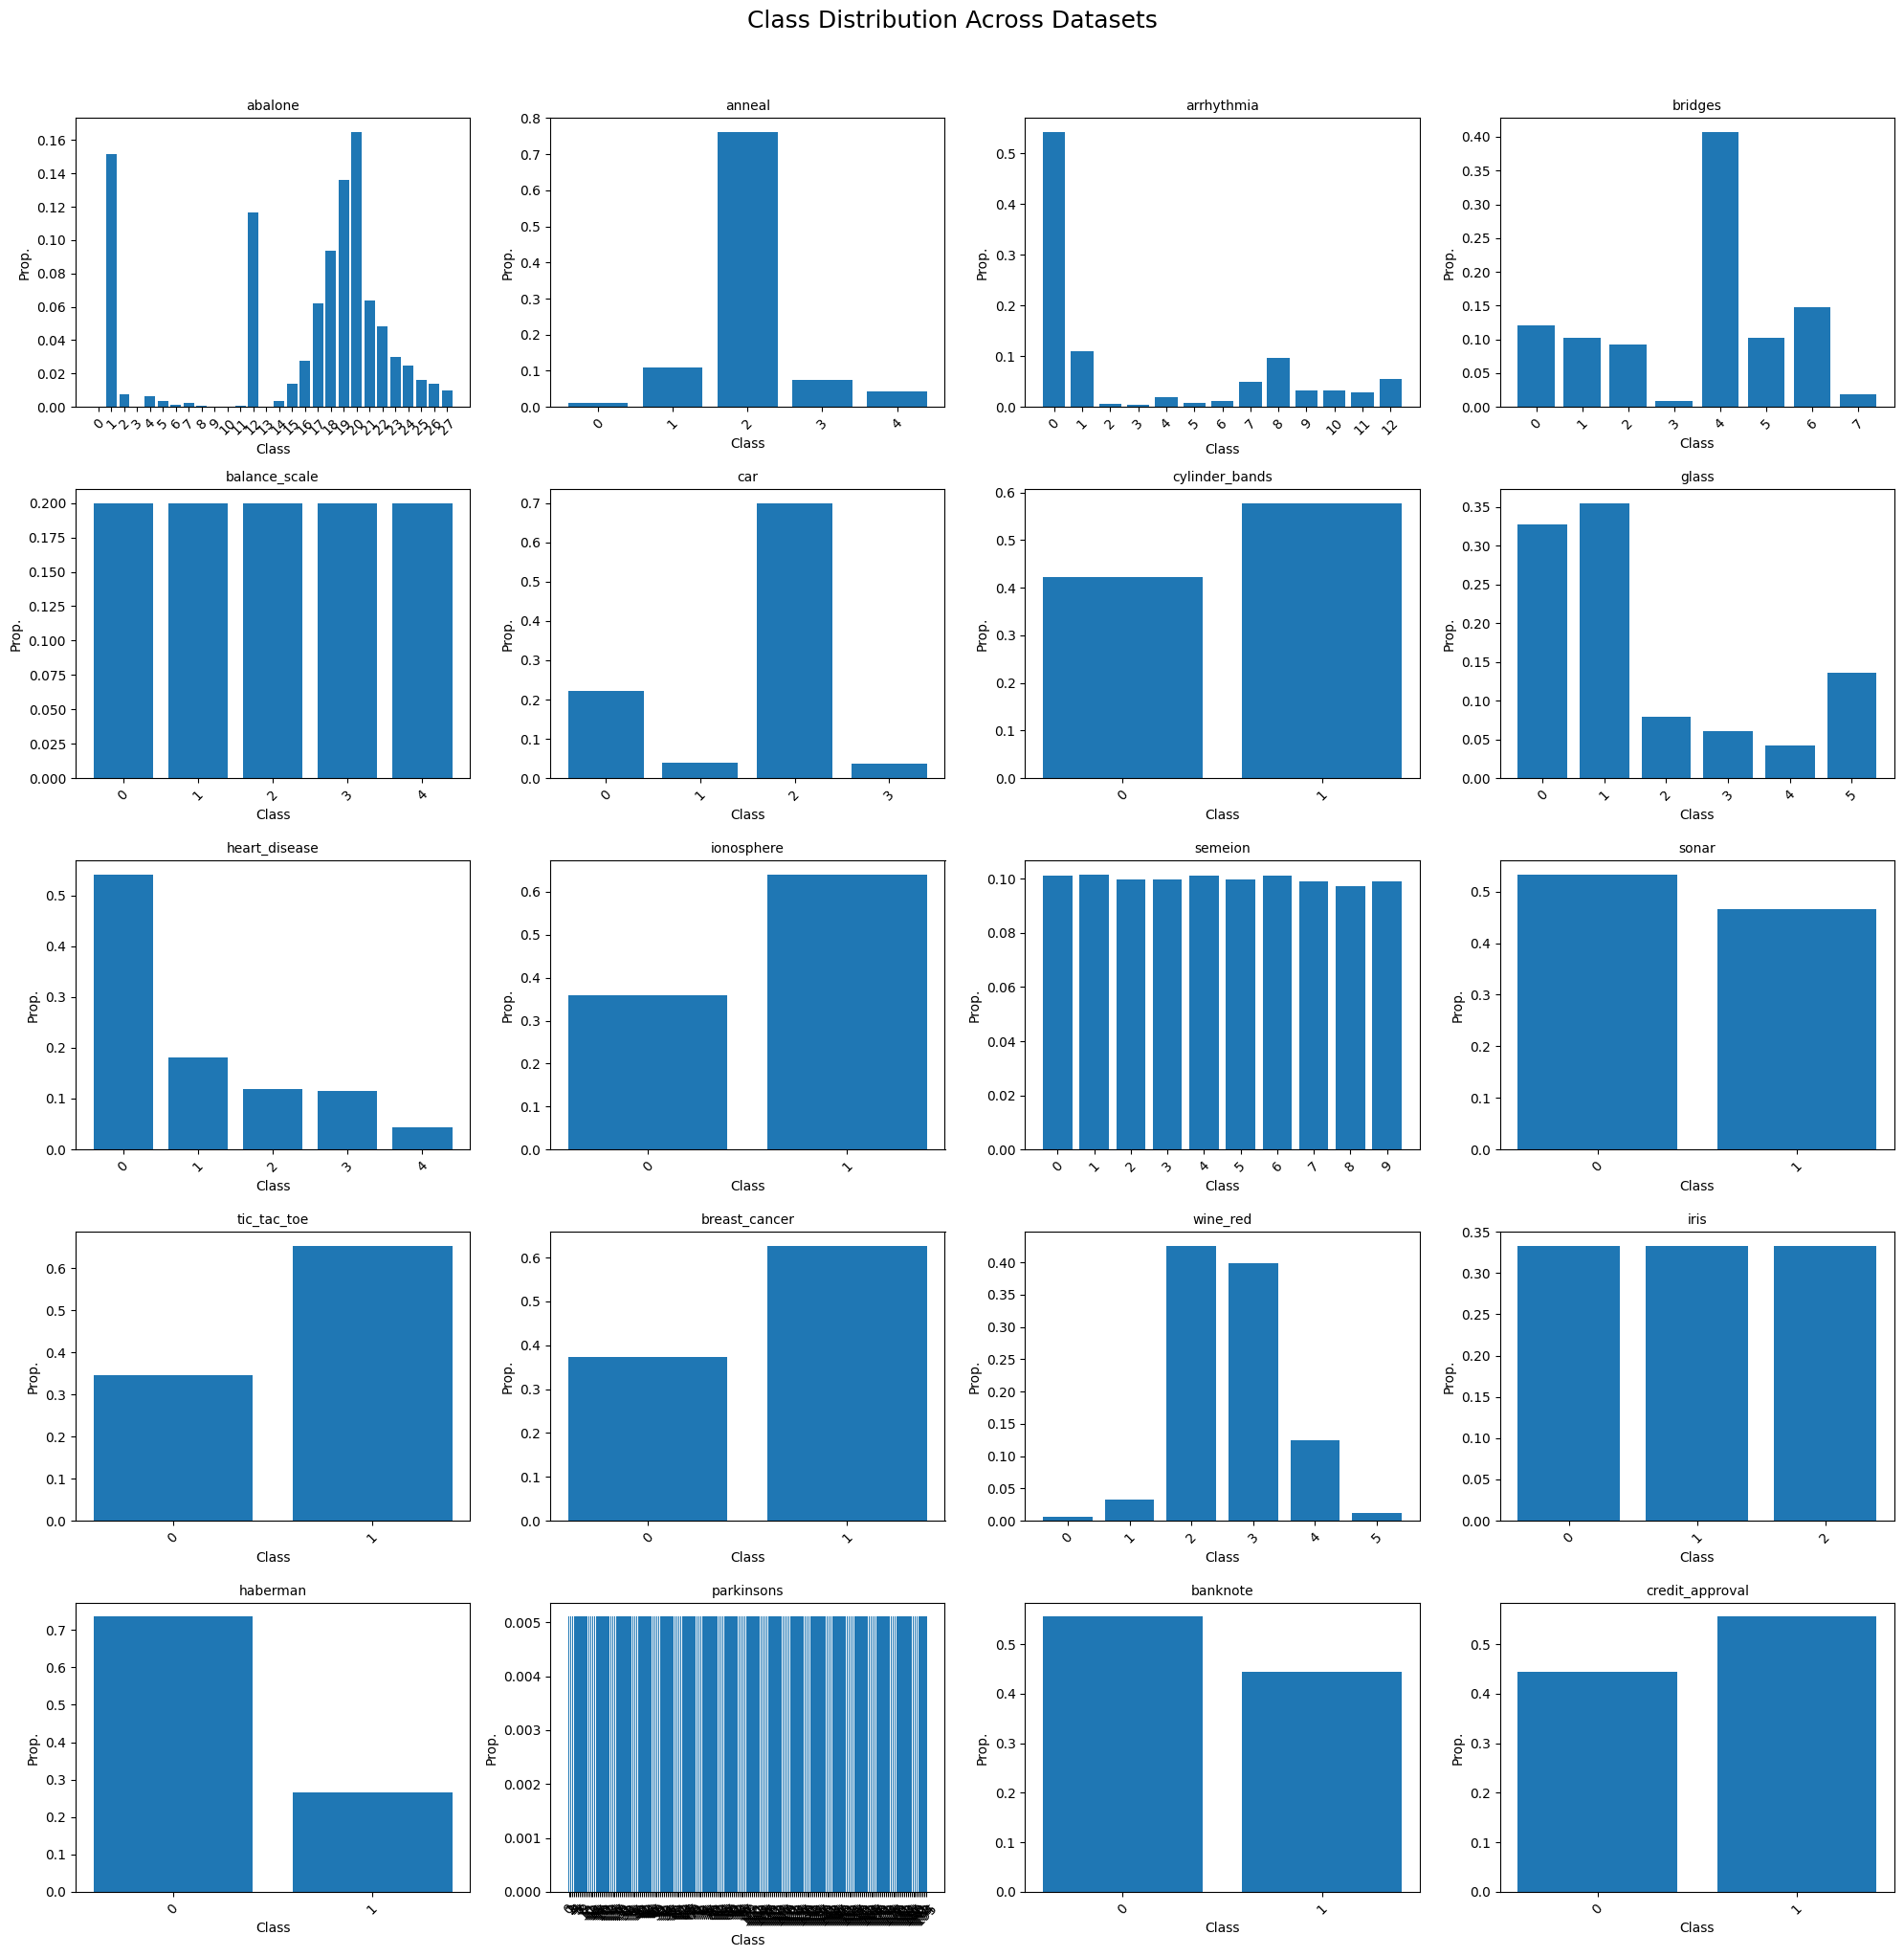

In [ ]:
# ==========================================
# 4. CLASS BALANCE PLOTS (ALL TOGETHER)
# ==========================================

datasets_names = list(loaded.keys())

n_datasets = len(datasets_names)

# Grid size
cols = 4
rows = math.ceil(n_datasets / cols)

fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 4))

# Flatten axes for easier iteration
axes = axes.flatten()

for idx, name in enumerate(datasets_names):

    temp = class_distribution_df[
        class_distribution_df["dataset"] == name
    ]

    axes[idx].bar(
        temp["class"].astype(str),
        temp["proportion"]
    )

    axes[idx].set_title(name, fontsize=10)
    axes[idx].set_xlabel("Class")
    axes[idx].set_ylabel("Prop.")

    axes[idx].tick_params(axis='x', rotation=45)

# Remove unused subplots
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Class Distribution Across Datasets",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()


## 5. Missing values analysis

This tells whether missing-value handling genes are likely to matter.

In [21]:
missing_rows = []
for name, obj in loaded.items():
    X = obj["X"]
    missing_by_feature = X.isna().mean().sort_values(ascending=False) * 100
    for feature, pct in missing_by_feature.items():
        if pct > 0:
            missing_rows.append({"dataset": name, "feature": feature, "missing_pct": pct})

missing_df = pd.DataFrame(missing_rows)
missing_df.to_csv(output_dir / "missing_values_by_feature.csv", index=False)
missing_df.head(30)


,dataset,feature,missing_pct
0,anneal,feature_022,100.000000
1,anneal,feature_029,100.000000
2,anneal,feature_030,100.000000
3,anneal,feature_025,100.000000
4,anneal,feature_028,100.000000
5,anneal,feature_018,100.000000
6,anneal,feature_013,99.874687
7,anneal,feature_023,99.749373
8,anneal,feature_026,99.373434
9,anneal,feature_020,99.122807


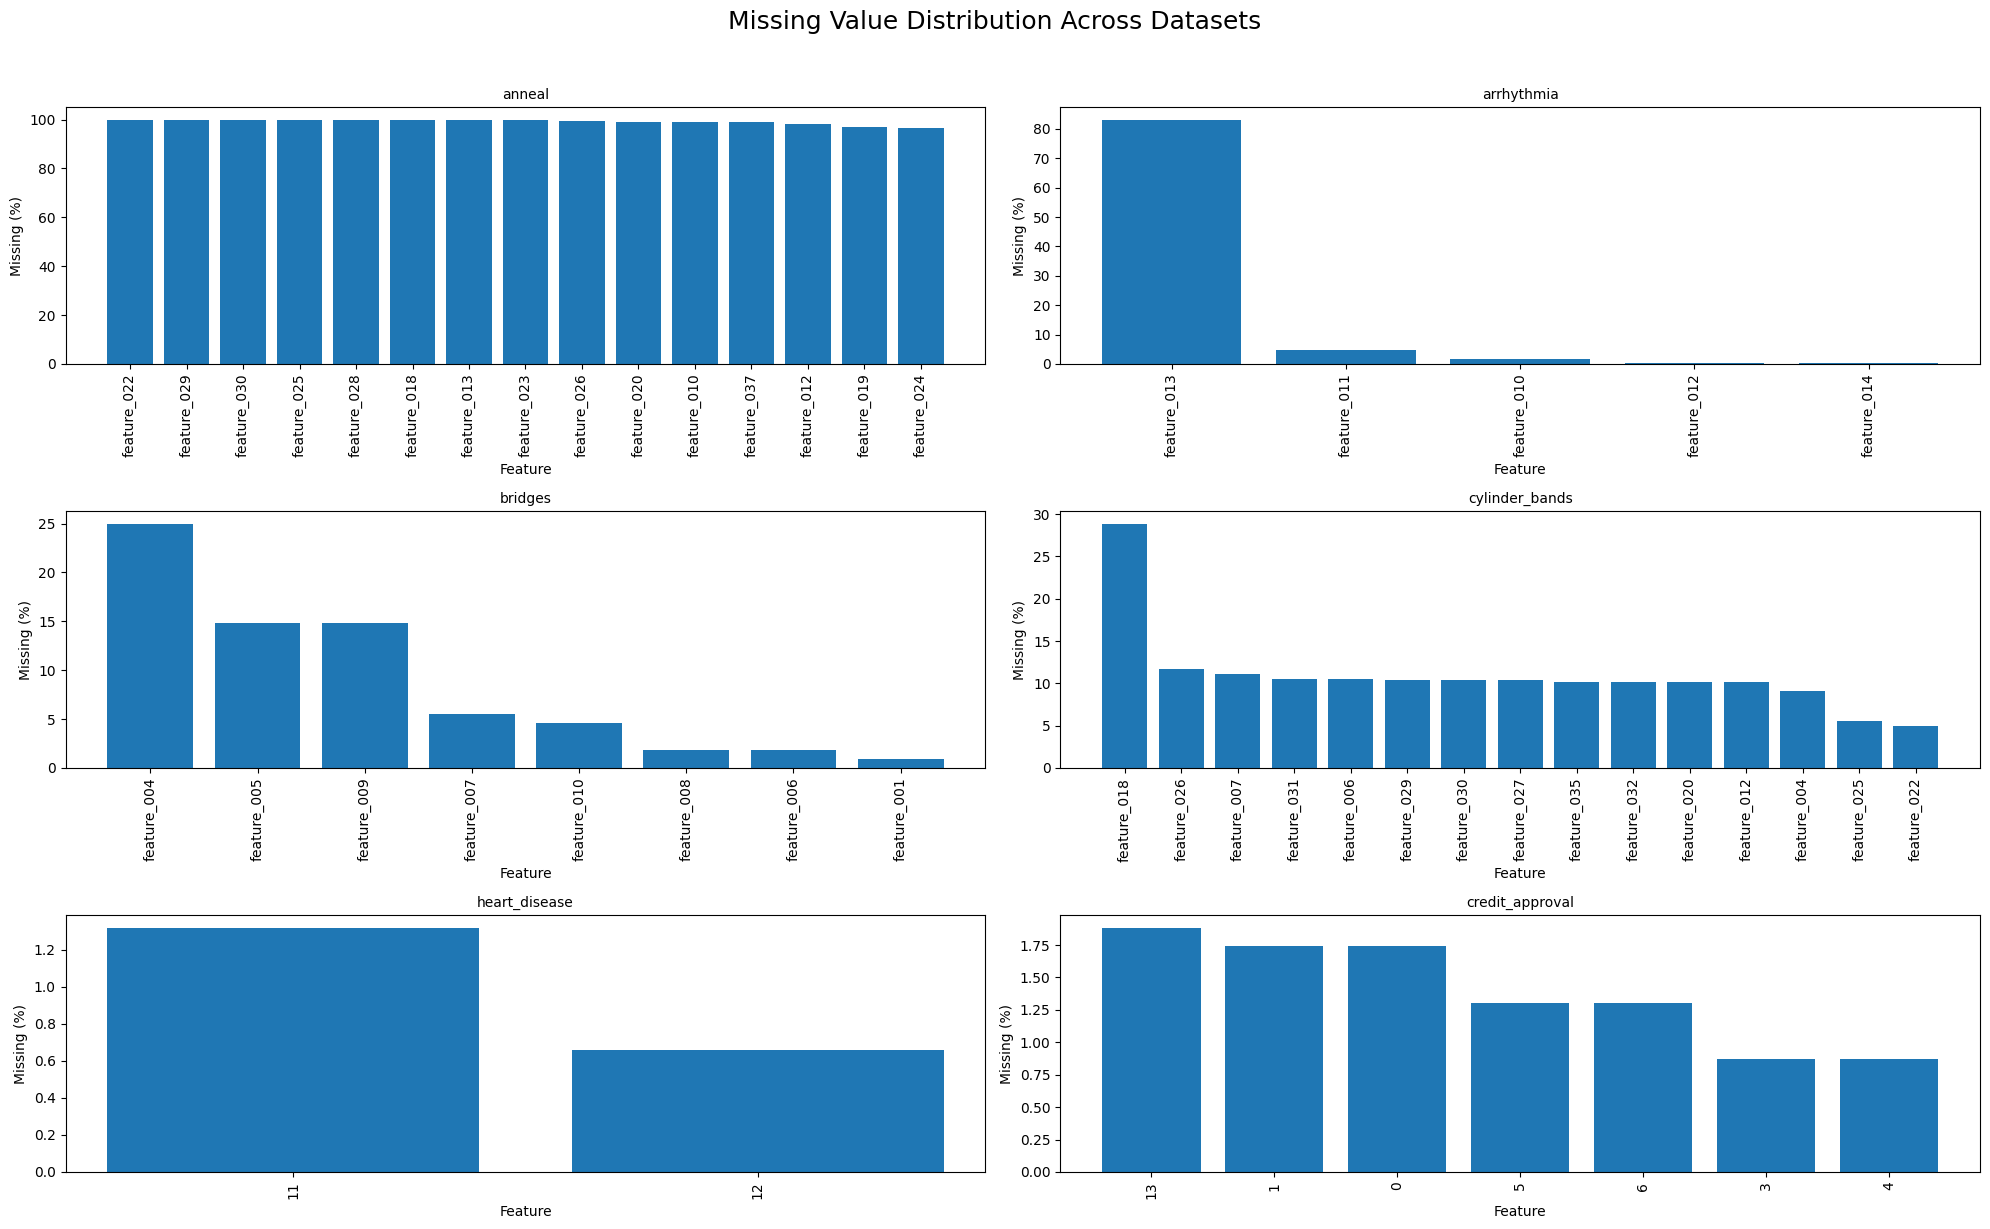

In [27]:
# ==========================================
# MISSING VALUE ANALYSIS (ALL TOGETHER)
# ==========================================
import math
if not missing_df.empty:

    datasets_with_missing = missing_df["dataset"].unique()

    n_datasets = len(datasets_with_missing)

    cols = 2
    rows = math.ceil(n_datasets / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(20, rows * 4)
    )

    axes = axes.flatten()

    for idx, name in enumerate(datasets_with_missing):

        temp = missing_df[
            missing_df["dataset"] == name
        ].head(15)

        axes[idx].bar(
            temp["feature"].astype(str),
            temp["missing_pct"]
        )

        axes[idx].set_title(name, fontsize=10)
        axes[idx].set_xlabel("Feature")
        axes[idx].set_ylabel("Missing (%)")

        axes[idx].tick_params(
            axis='x',
            rotation=90
        )

    # Remove empty subplots
    for j in range(idx + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(
        "Missing Value Distribution Across Datasets",
        fontsize=18,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## 6. Numeric descriptive statistics

Mean, median, standard deviation, skewness, kurtosis, and unique values.

In [8]:
descriptive_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        descriptive_rows.append({
            "dataset": name,
            "feature": feature,
            "mean": s.mean(),
            "median": s.median(),
            "std": s.std(),
            "min": s.min(),
            "max": s.max(),
            "skewness": skew(s),
            "kurtosis": kurtosis(s),
            "n_unique": s.nunique(),
        })

descriptive_df = pd.DataFrame(descriptive_rows)
descriptive_df.to_csv(output_dir / "numeric_descriptive_statistics.csv", index=False)
descriptive_df.head(20)


,dataset,feature,mean,median,std,min,max,skewness,kurtosis,n_unique
0,abalone,feature_001,0.523992,0.5450,0.120093,0.0750,0.8150,-0.639643,0.063108,134
1,abalone,feature_002,0.407881,0.4250,0.099240,0.0550,0.6500,-0.608979,-0.046857,111
2,abalone,feature_003,0.139516,0.1400,0.041827,0.0000,1.1300,3.127694,75.933099,51
3,abalone,feature_004,0.828742,0.7995,0.490389,0.0020,2.8255,0.530768,-0.025051,2429
4,abalone,feature_005,0.359367,0.3360,0.221963,0.0010,1.4880,0.718840,0.592975,1515
5,abalone,feature_006,0.180594,0.1710,0.109614,0.0005,0.7600,0.591640,0.082475,880
6,abalone,feature_007,0.238831,0.2340,0.139203,0.0015,1.0050,0.620704,0.529854,926
7,anneal,feature_003,3.547619,0.0000,13.592644,0.0000,70.0000,3.815705,13.020051,10
8,anneal,feature_004,11.748120,0.0000,24.621001,0.0000,85.0000,1.821492,1.835243,7
9,anneal,feature_007,2.223301,2.0000,0.659148,1.0000,5.0000,1.194513,3.939406,4


## 7. Low-variance features

Low-variance features may provide little information for splits.

In [9]:
low_variance_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) == 0:
            continue
        low_variance_rows.append({
            "dataset": name,
            "feature": feature,
            "variance": s.var(),
            "n_unique": s.nunique(),
        })

low_variance_df = pd.DataFrame(low_variance_rows).sort_values(["dataset", "variance"])
low_variance_df.to_csv(output_dir / "low_variance_features.csv", index=False)
low_variance_df.head(30)


,dataset,feature,variance,n_unique
2,abalone,feature_003,1.749503e-03,51
1,abalone,feature_002,9.848551e-03,111
5,abalone,feature_006,1.201528e-02,880
0,abalone,feature_001,1.442231e-02,134
6,abalone,feature_007,1.937738e-02,926
4,abalone,feature_005,4.926755e-02,1515
3,abalone,feature_004,2.404814e-01,2429
16,anneal,feature_037,1.111111e-01,2
11,anneal,feature_012,2.564103e-01,2
9,anneal,feature_007,4.344755e-01,4


## 8. Outlier analysis

Outliers are estimated using IQR and z-score. They can affect threshold-based splits.

In [10]:
outlier_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    for feature in numeric_X.columns:
        s = numeric_X[feature].dropna()
        if len(s) < 3:
            continue
        q1, q3 = np.percentile(s, [25, 75])
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        iqr_outliers = ((s < lower) | (s > upper)).mean() * 100
        z_outliers = (np.abs(zscore(s)) > 3).mean() * 100
        outlier_rows.append({
            "dataset": name,
            "feature": feature,
            "iqr_outlier_pct": iqr_outliers,
            "zscore_outlier_pct": z_outliers,
        })

outlier_df = pd.DataFrame(outlier_rows)
outlier_df.to_csv(output_dir / "outlier_analysis.csv", index=False)
outlier_df.sort_values(["dataset", "iqr_outlier_pct"], ascending=[True, False]).head(30)


,dataset,feature,iqr_outlier_pct,zscore_outlier_pct
1,abalone,feature_002,1.412497,0.311228
0,abalone,feature_001,1.173091,0.359109
4,abalone,feature_005,1.149150,0.885803
6,abalone,feature_007,0.837922,0.646397
3,abalone,feature_004,0.718219,0.454872
2,abalone,feature_003,0.694278,0.119703
5,abalone,feature_006,0.622456,0.526694
14,anneal,feature_034,22.431078,0.000000
8,anneal,feature_004,19.799499,0.000000
16,anneal,feature_037,11.111111,0.000000


## 9. Feature-class separability tests

For numeric features:

- ANOVA checks whether mean values differ across classes.
- Kruskal-Wallis is a non-parametric alternative.

Small p-values suggest that the feature may help separate classes.

In [11]:
separability_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    numeric_X = X.select_dtypes(include=[np.number])
    classes = np.unique(y)
    for feature in numeric_X.columns:
        groups = []
        for cls in classes:
            values = numeric_X.loc[y == cls, feature].dropna().values
            if len(values) > 1:
                groups.append(values)
        if len(groups) < 2:
            continue
        try:
            anova_stat, anova_p = f_oneway(*groups)
        except Exception:
            anova_stat, anova_p = np.nan, np.nan
        try:
            kruskal_stat, kruskal_p = kruskal(*groups)
        except Exception:
            kruskal_stat, kruskal_p = np.nan, np.nan
        separability_rows.append({
            "dataset": name,
            "feature": feature,
            "anova_p": anova_p,
            "kruskal_p": kruskal_p,
            "anova_stat": anova_stat,
            "kruskal_stat": kruskal_stat,
        })

separability_df = pd.DataFrame(separability_rows)
separability_df.to_csv(output_dir / "feature_class_separability_tests.csv", index=False)
separability_df.sort_values(["dataset", "kruskal_p"]).head(30)


,dataset,feature,anova_p,kruskal_p,anova_stat,kruskal_stat
0,abalone,feature_001,0.000000e+00,0.000000e+00,228.612857,1883.888382
1,abalone,feature_002,0.000000e+00,0.000000e+00,238.311683,1941.808839
2,abalone,feature_003,0.000000e+00,0.000000e+00,150.803817,2009.722020
3,abalone,feature_004,0.000000e+00,0.000000e+00,138.677333,1945.096267
4,abalone,feature_005,0.000000e+00,0.000000e+00,98.630296,1650.491201
5,abalone,feature_006,0.000000e+00,0.000000e+00,126.753934,1894.927766
6,abalone,feature_007,0.000000e+00,0.000000e+00,179.518538,2191.917129
8,anneal,feature_004,3.265697e-78,2.691340e-43,116.605005,205.324516
10,anneal,feature_008,2.641122e-26,1.498158e-22,34.127283,108.529543
12,anneal,feature_032,4.937191e-05,9.863091e-10,6.351938,47.908178


## 10. Correlation analysis

Highly correlated numeric features may indicate redundancy.

In [12]:
correlation_rows = []
for name, obj in loaded.items():
    numeric_X = obj["X"].select_dtypes(include=[np.number])
    if numeric_X.shape[1] < 2:
        continue
    corr = numeric_X.corr(method="spearman").abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    high_pairs = upper.stack().reset_index()
    high_pairs.columns = ["feature_1", "feature_2", "abs_spearman_corr"]
    high_pairs = high_pairs.sort_values("abs_spearman_corr", ascending=False)
    for _, row in high_pairs.head(20).iterrows():
        correlation_rows.append({
            "dataset": name,
            "feature_1": row["feature_1"],
            "feature_2": row["feature_2"],
            "abs_spearman_corr": row["abs_spearman_corr"],
        })

correlation_df = pd.DataFrame(correlation_rows)
correlation_df.to_csv(output_dir / "top_feature_correlations.csv", index=False)
correlation_df.head(30)


,dataset,feature_1,feature_2,abs_spearman_corr
0,abalone,feature_001,feature_002,0.983319
1,abalone,feature_004,feature_005,0.977060
2,abalone,feature_004,feature_006,0.975252
3,abalone,feature_001,feature_004,0.972633
4,abalone,feature_002,feature_004,0.971324
5,abalone,feature_004,feature_007,0.969426
6,abalone,feature_001,feature_005,0.956830
7,abalone,feature_002,feature_007,0.954149
8,abalone,feature_001,feature_006,0.952658
9,abalone,feature_002,feature_005,0.950472


## 11. Univariate feature importance

Mutual Information and Chi-square scores estimate individual predictive signal per feature.

In [13]:
def make_encoded_matrix(X):
    X_copy = X.copy()
    numeric_cols = X_copy.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X_copy.columns if c not in numeric_cols]
    parts = []
    feature_names = []

    if numeric_cols:
        X_num = Pipeline([("imputer", SimpleImputer(strategy="median"))]).fit_transform(X_copy[numeric_cols])
        parts.append(X_num)
        feature_names.extend(numeric_cols)

    if categorical_cols:
        X_cat = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
        ]).fit_transform(X_copy[categorical_cols].astype(str))
        parts.append(X_cat)
        feature_names.extend(categorical_cols)

    if not parts:
        return None, []
    return np.hstack(parts), feature_names

importance_rows = []
for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    X_encoded, feature_names = make_encoded_matrix(X)
    if X_encoded is None:
        continue
    try:
        mi = mutual_info_classif(X_encoded, y, random_state=42)
    except Exception:
        mi = np.full(X_encoded.shape[1], np.nan)
    try:
        X_nonnegative = MinMaxScaler().fit_transform(X_encoded)
        chi_scores, chi_p = chi2(X_nonnegative, y)
    except Exception:
        chi_scores = np.full(X_encoded.shape[1], np.nan)
        chi_p = np.full(X_encoded.shape[1], np.nan)
    for feature, mi_score, chi_score, p_val in zip(feature_names, mi, chi_scores, chi_p):
        importance_rows.append({
            "dataset": name,
            "feature": feature,
            "mutual_information": mi_score,
            "chi2_score": chi_score,
            "chi2_p": p_val,
        })

importance_df = pd.DataFrame(importance_rows)
importance_df.to_csv(output_dir / "univariate_feature_importance.csv", index=False)
importance_df.sort_values(["dataset", "mutual_information"], ascending=[True, False]).head(30)


,dataset,feature,mutual_information,chi2_score,chi2_p
6,abalone,feature_007,0.464273,166.254507,5.391010e-22
1,abalone,feature_002,0.406307,109.903884,5.762068e-12
3,abalone,feature_004,0.390034,182.963465,4.135206e-25
2,abalone,feature_003,0.375622,20.734631,7.985581e-01
5,abalone,feature_006,0.374857,147.825210,1.273761e-18
0,abalone,feature_001,0.371289,99.863833,2.709953e-10
4,abalone,feature_005,0.329069,133.046654,5.648614e-16
7,abalone,feature_000,0.162174,5.127324,9.999987e-01
13,anneal,feature_018,0.330094,5.256515,2.619753e-01
25,anneal,feature_001,0.287563,55.665645,2.356383e-11


## 12. Baseline performance and CV variability

Baselines using macro-F1:

- Dummy classifier
- Default decision tree
- Logistic regression

The standard deviation across folds is useful for discussing dataset instability and SDD.

In [14]:
def build_preprocessor(X, for_linear=False):
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if for_linear:
        numeric_steps.append(("scaler", StandardScaler()))
    transformers = []
    if numeric_cols:
        transformers.append(("num", Pipeline(numeric_steps), numeric_cols))
    if categorical_cols:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_cols,
        ))
    return ColumnTransformer(transformers)


def safe_cv(y, desired_splits=5):
    counts = np.bincount(y)
    min_count = counts.min()
    if min_count < 2:
        return None
    n_splits = min(desired_splits, min_count)
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

baseline_rows = []
scorer = make_scorer(f1_score, average="macro")

for name, obj in loaded.items():
    X, y = obj["X"], obj["y"]
    cv = safe_cv(y, desired_splits=5)
    if cv is None:
        print(f"[SKIP] {name}: not enough samples in at least one class for CV.")
        continue

    models = {
        "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),
        "decision_tree_default": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=False)),
            ("model", DecisionTreeClassifier(random_state=42)),
        ]),
        "logistic_regression": Pipeline([
            ("preprocess", build_preprocessor(X, for_linear=True)),
            ("model", LogisticRegression(max_iter=1000, random_state=42)),
        ]),
    }

    for model_name, model in models.items():
        try:
            scores = cross_val_score(model, X, y, cv=cv, scoring=scorer, n_jobs=-1)
            baseline_rows.append({
                "dataset": name,
                "model": model_name,
                "cv_folds": cv.get_n_splits(),
                "f1_macro_mean": scores.mean(),
                "f1_macro_std": scores.std(),
                "f1_macro_min": scores.min(),
                "f1_macro_max": scores.max(),
                "scores": list(scores),
            })
        except Exception as e:
            baseline_rows.append({
                "dataset": name,
                "model": model_name,
                "cv_folds": cv.get_n_splits(),
                "f1_macro_mean": np.nan,
                "f1_macro_std": np.nan,
                "f1_macro_min": np.nan,
                "f1_macro_max": np.nan,
                "scores": [],
                "error": str(e),
            })

baseline_df = pd.DataFrame(baseline_rows)
baseline_df.to_csv(output_dir / "baseline_cv_performance.csv", index=False)
baseline_df.sort_values(["dataset", "model"])


[SKIP] abalone: not enough samples in at least one class for CV.
[SKIP] bridges: not enough samples in at least one class for CV.
[SKIP] parkinsons: not enough samples in at least one class for CV.


,dataset,model,cv_folds,f1_macro_mean,f1_macro_std,f1_macro_min,f1_macro_max,scores
1,anneal,decision_tree_default,5,0.933105,0.025203,0.885443,0.960876,"[0.9403969767606132, 0.9389183365653955, 0.885..."
0,anneal,dummy_most_frequent,5,0.172973,0.000094,0.172857,0.173050,"[0.17304964539007092, 0.17304964539007092, 0.1..."
2,anneal,logistic_regression,5,0.747051,0.072195,0.643607,0.845381,"[0.7667273996685762, 0.6436065573770493, 0.688..."
4,arrhythmia,decision_tree_default,2,0.301108,0.000511,0.300596,0.301619,"[0.30059647216391056, 0.301618726869563]"
3,arrhythmia,dummy_most_frequent,2,0.054078,0.000143,0.053935,0.054221,"[0.05393457117595049, 0.05422085078245537]"
5,arrhythmia,logistic_regression,2,0.408049,0.035601,0.372449,0.443650,"[0.44364994467363583, 0.3724488227265041]"
7,balance_scale,decision_tree_default,5,0.078592,0.009268,0.066495,0.092028,"[0.06649477973007385, 0.07029411764705881, 0.0..."
6,balance_scale,dummy_most_frequent,5,0.066667,0.000000,0.066667,0.066667,"[0.06666666666666667, 0.06666666666666667, 0.0..."
8,balance_scale,logistic_regression,5,0.275374,0.011633,0.255480,0.289656,"[0.27612518200753494, 0.2834849276721694, 0.28..."
46,banknote,decision_tree_default,5,0.983026,0.006845,0.974202,0.992634,"[0.9778225806451613, 0.9926336654880532, 0.981..."


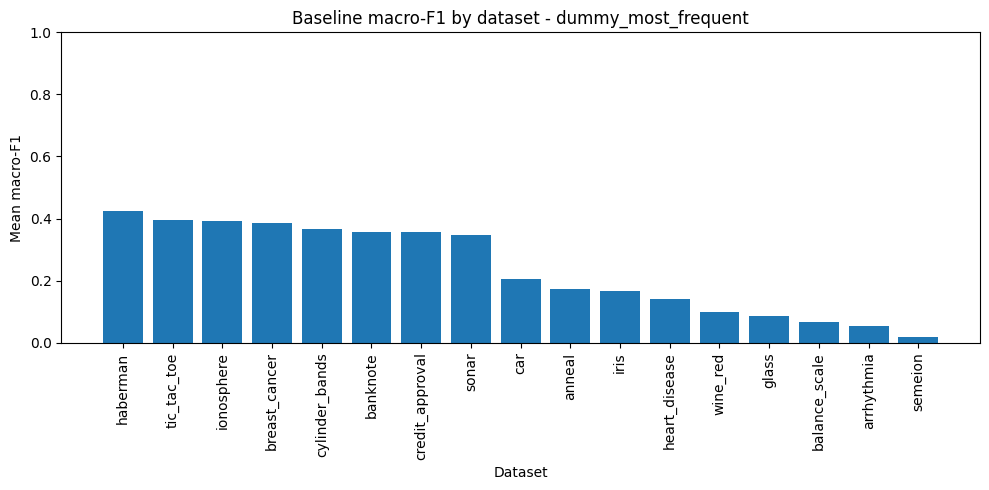

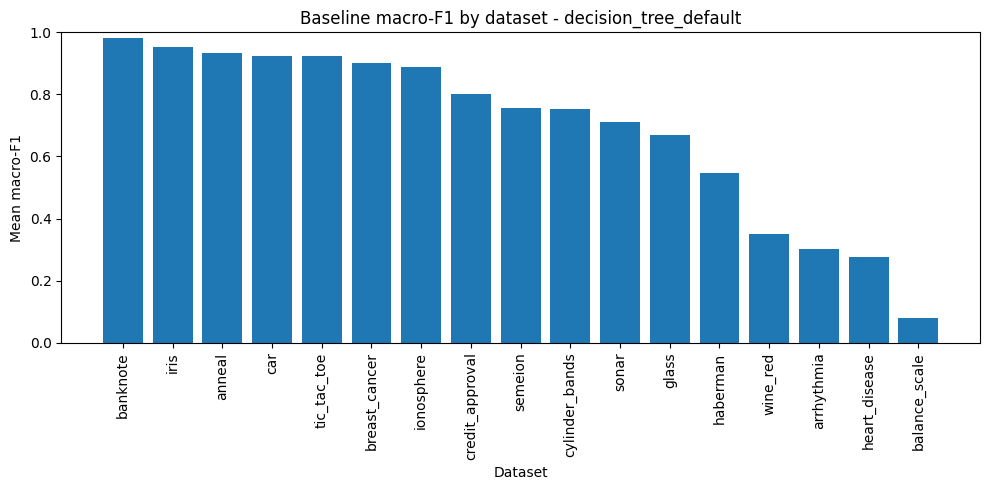

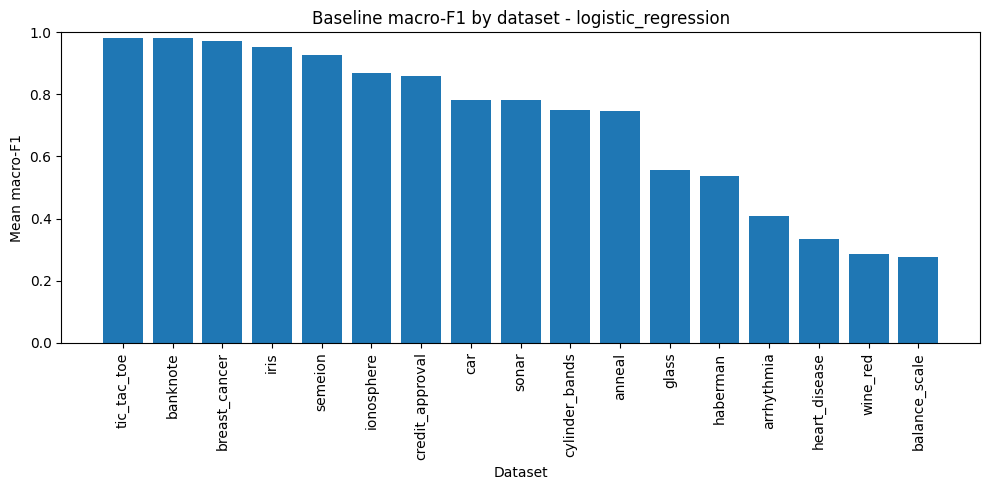

In [24]:
plot_df = baseline_df.dropna(subset=["f1_macro_mean"])
for model_name in plot_df["model"].unique():
    temp = plot_df[plot_df["model"] == model_name].sort_values("f1_macro_mean", ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(temp["dataset"], temp["f1_macro_mean"])
    plt.title(f"Baseline macro-F1 by dataset - {model_name}")
    plt.xlabel("Dataset")
    plt.ylabel("Mean macro-F1")
    plt.xticks(rotation=90)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()


## 13. Dataset similarity based on class distributions

Uses Jensen-Shannon distance between class distributions. This is a rough comparison because datasets may have different numbers of classes.

In [16]:
names = list(loaded.keys())
max_classes = max(len(np.unique(loaded[name]["y"])) for name in names)

class_vectors = {}
for name in names:
    y = loaded[name]["y"]
    counts = np.bincount(y, minlength=max_classes)
    class_vectors[name] = counts / counts.sum()

similarity_matrix = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        similarity_matrix.loc[a, b] = jensenshannon(class_vectors[a], class_vectors[b])

similarity_matrix.to_csv(output_dir / "class_distribution_js_distance.csv")
similarity_matrix


,abalone,anneal,arrhythmia,bridges,balance_scale,car,cylinder_bands,glass,heart_disease,ionosphere,semeion,sonar,tic_tac_toe,breast_cancer,wine_red,iris,haberman,parkinsons,banknote,credit_approval
abalone,0.000000,0.756184,0.722341,0.749455,0.735308,0.788219,0.711055,0.711710,0.743374,0.706102,0.749452,0.720994,0.705178,0.707132,0.782589,0.723265,0.745300,0.739883,0.723156,0.712943
anneal,0.756184,0.000000,0.737804,0.608591,0.434900,0.294972,0.719662,0.579297,0.550975,0.716556,0.587373,0.726266,0.715996,0.717189,0.332094,0.457820,0.743636,0.803070,0.727751,0.720884
arrhythmia,0.722341,0.737804,0.000000,0.592111,0.563067,0.627196,0.459309,0.470979,0.422770,0.482947,0.496202,0.423523,0.487891,0.477646,0.756336,0.511231,0.379487,0.771652,0.417403,0.451422
bridges,0.749455,0.608591,0.592111,0.000000,0.433484,0.620814,0.637186,0.466595,0.532851,0.640019,0.396738,0.635143,0.640734,0.639298,0.579924,0.576199,0.641143,0.784983,0.635161,0.636476
balance_scale,0.735308,0.434900,0.563067,0.433484,0.000000,0.450339,0.525455,0.355987,0.282011,0.529354,0.462465,0.524102,0.530408,0.528311,0.369654,0.404841,0.540042,0.795887,0.524632,0.524623
car,0.788219,0.294972,0.627196,0.620814,0.450339,0.000000,0.641551,0.531100,0.445450,0.651032,0.599801,0.627987,0.653074,0.648867,0.464923,0.343209,0.612047,0.806259,0.625748,0.638485
cylinder_bands,0.711055,0.719662,0.459309,0.637186,0.525455,0.641551,0.000000,0.355760,0.392572,0.045853,0.649102,0.078954,0.055029,0.035872,0.782570,0.367074,0.226339,0.815284,0.094330,0.016199
glass,0.711710,0.579297,0.470979,0.466595,0.355987,0.531100,0.355760,0.000000,0.284429,0.362352,0.465541,0.355548,0.364221,0.360524,0.595333,0.353211,0.392010,0.793042,0.357165,0.354554
heart_disease,0.743374,0.550975,0.422770,0.532851,0.282011,0.445450,0.392572,0.284429,0.000000,0.416398,0.517074,0.358461,0.421458,0.410999,0.549894,0.324402,0.327692,0.798535,0.353042,0.384799
ionosphere,0.706102,0.716556,0.482947,0.640019,0.529354,0.651032,0.045853,0.362352,0.416398,0.000000,0.650953,0.124574,0.009189,0.009990,0.781821,0.374799,0.270783,0.815375,0.139873,0.062028


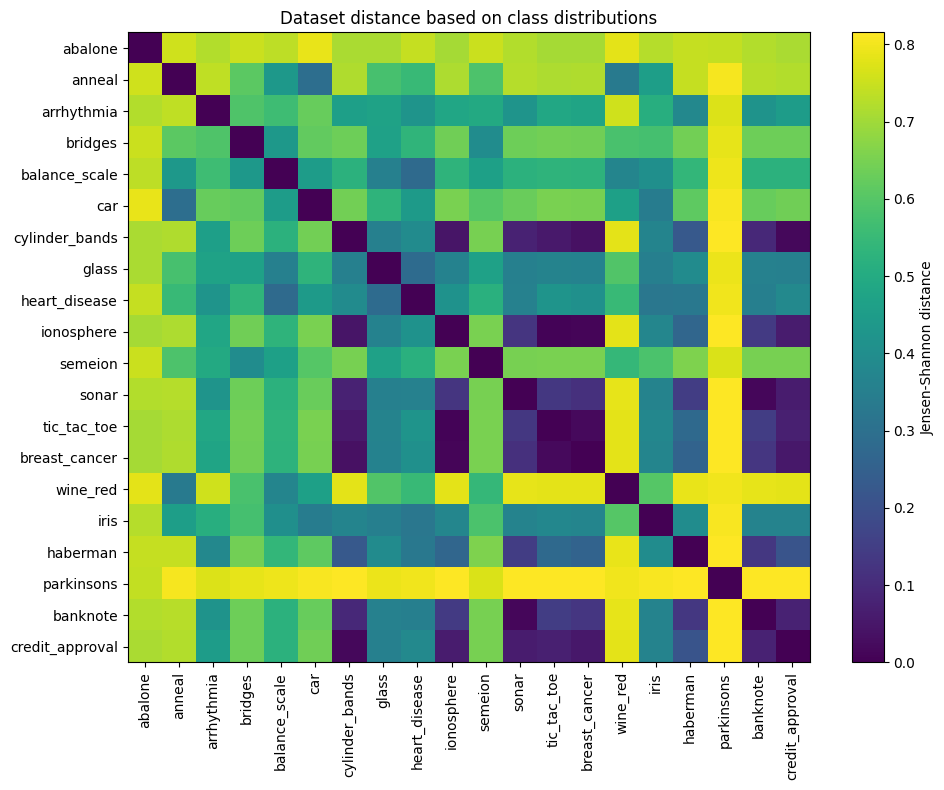

In [17]:
plt.figure(figsize=(10, 8))
plt.imshow(similarity_matrix.astype(float), aspect="auto")
plt.colorbar(label="Jensen-Shannon distance")
plt.xticks(range(len(names)), names, rotation=90)
plt.yticks(range(len(names)), names)
plt.title("Dataset distance based on class distributions")
plt.tight_layout()
plt.show()


## 14. Thesis-oriented interpretation table

This final table merges the most useful indicators for discussion.

In [18]:
best_tree = baseline_df[baseline_df["model"] == "decision_tree_default"][[
    "dataset", "f1_macro_mean", "f1_macro_std"
]].rename(columns={
    "f1_macro_mean": "baseline_tree_f1_mean",
    "f1_macro_std": "baseline_tree_f1_std",
})

final_interpretation_df = summary_df.merge(best_tree, on="dataset", how="left")
final_interpretation_df["possible_issue"] = ""
final_interpretation_df.loc[final_interpretation_df["imbalance_ratio"] > 2, "possible_issue"] += "class imbalance; "
final_interpretation_df.loc[final_interpretation_df["missing_pct"] > 5, "possible_issue"] += "missing values; "
final_interpretation_df.loc[final_interpretation_df["samples_per_feature"] < 10, "possible_issue"] += "low samples/features ratio; "
final_interpretation_df.loc[final_interpretation_df["baseline_tree_f1_std"] > 0.10, "possible_issue"] += "high CV variability; "
final_interpretation_df["possible_issue"] = final_interpretation_df["possible_issue"].replace("", "none obvious")

final_interpretation_df.to_csv(output_dir / "thesis_dataset_interpretation_summary.csv", index=False)
final_interpretation_df.sort_values("dataset")


,dataset,n_samples,n_features,n_numeric,n_categorical,n_classes,missing_pct,class_entropy,imbalance_ratio,samples_per_feature,baseline_tree_f1_mean,baseline_tree_f1_std,possible_issue
0,abalone,4177,8,7,1,28,0.000000,3.602007,689.000000,522.125000,NaN,NaN,class imbalance;
1,anneal,798,38,16,22,5,64.938662,1.190925,76.000000,21.000000,0.933105,0.025203,class imbalance; missing values;
2,arrhythmia,452,279,279,0,13,0.323532,2.401386,122.500000,1.620072,0.301108,0.000511,class imbalance; low samples/features ratio;
3,balance_scale,625,4,3,1,5,0.000000,2.321928,1.000000,156.250000,0.078592,0.009268,none obvious
4,banknote,1372,4,4,0,2,0.000000,0.991128,1.249180,343.000000,0.983026,0.006845,none obvious
5,breast_cancer,569,30,30,0,2,0.000000,0.952635,1.683962,18.966667,0.902794,0.031689,none obvious
6,bridges,108,11,4,7,8,6.313131,2.461855,44.000000,9.818182,NaN,NaN,class imbalance; missing values; low samples/f...
7,car,1728,6,0,6,4,0.000000,1.205741,18.615385,288.000000,0.924437,0.044219,class imbalance;
8,credit_approval,690,15,6,9,2,0.647343,0.991231,1.247557,46.000000,0.799980,0.028170,none obvious
9,cylinder_bands,540,39,24,15,2,4.743590,0.982474,1.368421,13.846154,0.751650,0.050389,none obvious



Justify why each dataset may affect the GA differently:

- Dataset imbalance can affect macro-F1 and make some datasets harder.
- Missing values make missing-value handling genes more relevant.
- Strong univariate feature importance may indicate that simple trees can already perform well.
- High CV variability means performance differences should be interpreted carefully.
- Dataset differences help explain why SDD alone may encourage equal behavior without necessarily improving absolute F1.